## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sam Leal

**Date:** 10/14/2026

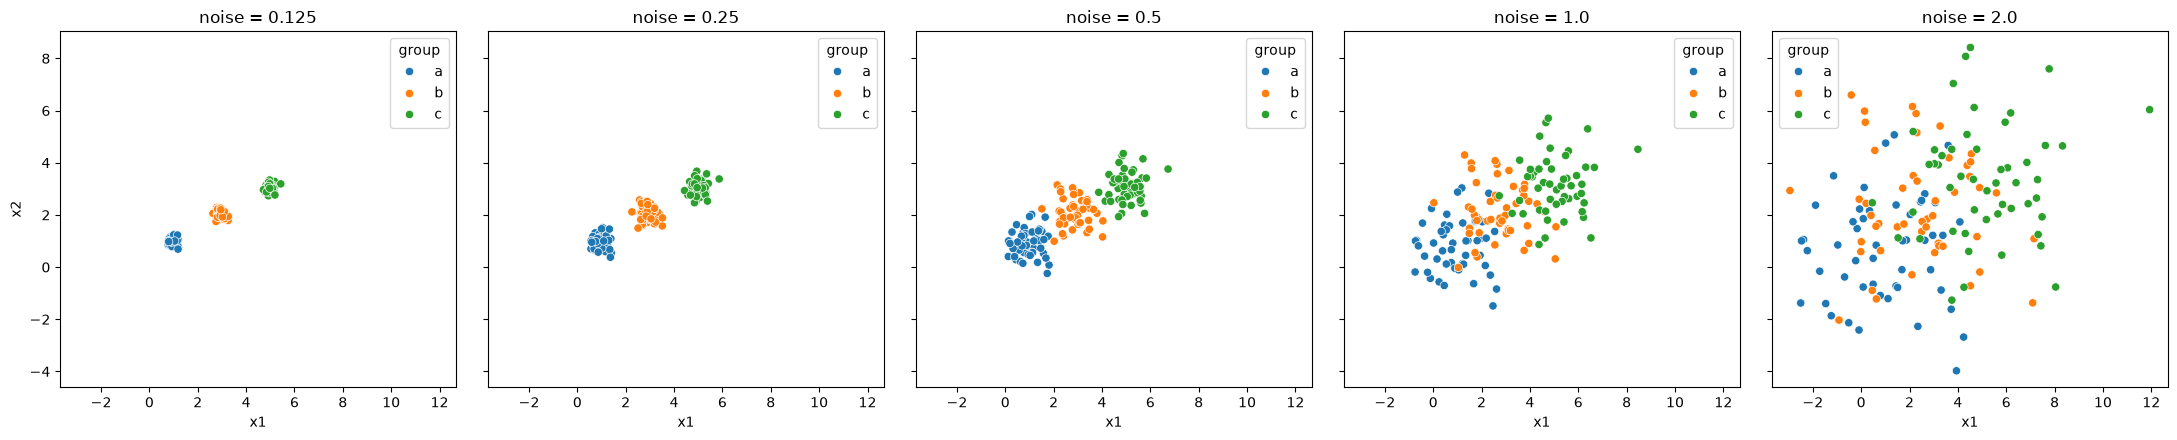

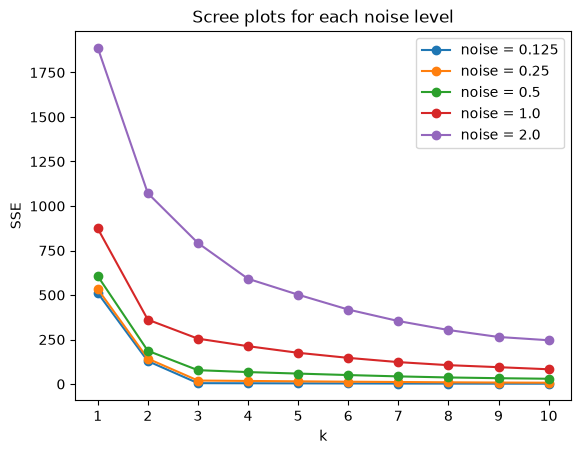

In [16]:
# Your Phase 1 solution to the problem goes here.
#Q1 part 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt        
import seaborn as sns                  
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

#part 2
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharex=True, sharey=True)

sns.scatterplot(data=df0_125, x='x1', y='x2', hue='group', ax=axes[0]).set(title="noise = 0.125")
sns.scatterplot(data=df0_25,  x='x1', y='x2', hue='group', ax=axes[1]).set(title="noise = 0.25")
sns.scatterplot(data=df0_5,   x='x1', y='x2', hue='group', ax=axes[2]).set(title="noise = 0.5")
sns.scatterplot(data=df1_0,   x='x1', y='x2', hue='group', ax=axes[3]).set(title="noise = 1.0")
sns.scatterplot(data=df2_0,   x='x1', y='x2', hue='group', ax=axes[4]).set(title="noise = 2.0")

plt.tight_layout()
plt.show()
# When the noise is low (0.125 and 0.25), the three groups are really tight blobs with lots of space between them, so they’re super easy to tell apart. At 0.5 they’re still mostly separate, but the edges start running into each other. By 1.0 they overlap a lot, and at 2.0 it basically just looks like one big messy cloud. So the clusters only stay distinct while the spread within each group is small compared with how far apart the centers are (about 2.2).

#part 3
ks = np.arange(1, 11)

def scree(df):
    X = df[['x1', 'x2']]
    return [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
            for k in ks]

SSE0_125 = scree(df0_125)
SSE0_25  = scree(df0_25)
SSE0_5   = scree(df0_5)
SSE1_0   = scree(df1_0)
SSE2_0   = scree(df2_0)

# All five scree curves on one canvas
plt.plot(ks, SSE0_125, marker='o', label='noise = 0.125')
plt.plot(ks, SSE0_25,  marker='o', label='noise = 0.25')
plt.plot(ks, SSE0_5,   marker='o', label='noise = 0.5')
plt.plot(ks, SSE1_0,   marker='o', label='noise = 1.0')
plt.plot(ks, SSE2_0,   marker='o', label='noise = 2.0')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree plots for each noise level')
plt.xticks(ks)
plt.legend()
plt.show()
# With low noise (0.125 and 0.25) there’s a really obvious elbow at k = 3. SSE drops a ton up to 3 clusters and then pretty much flattens out. At 0.5 you can still see the elbow at 3, but it’s softer. At 1.0 and 2.0 the curve just slopes down smoothly, and there’s no clear corner. The whole curve also sits higher with more noise, since there’s extra spread that no set of centroids can get rid of.
# When the noise is low, picking k = 3 is a no-brainer. As the noise goes up it gets harder, and at 2.0 you could honestly argue for 2, 3, 4 or more. That lines up with the scatterplot, where the groups have basically blended into one cloud. For example, at noise = 0.125 the SSE drop from 2 to 3 clusters is about 200 times bigger than the drop from 3 to 4, but at noise = 2.0 it’s only about 1.4 times bigger.

#part 4
# SSE is basically how far points are from their cluster’s centroid, and adding a cluster always makes it go down. When k is smaller than the real number of groups, some clusters get stuck covering more than one group, so each new cluster splits off a real group and SSE drops a lot. In the noise = 0.125 data, SSE goes from about 512 at k = 1 to 129 at k = 2 to just 5 at k = 3. Once each real group has its own cluster, adding more just splits up the random noise inside a group, so SSE barely changes (about 4.9 to 4.3 going from 3 to 4). The elbow is the spot where you go from big drops (finding real groups) to tiny drops (just fitting noise), and that’s why it points to k = 3.
# The simulation also shows the elbow only works when the groups are far apart compared with how spread out they are. With more noise, the groups overlap, so separating them doesn’t help as much. Each group is also more spread out, so splitting one helps more than before. At noise = 2.0 those two effects are about the same size, so the elbow pretty much disappears.


(148, 7)


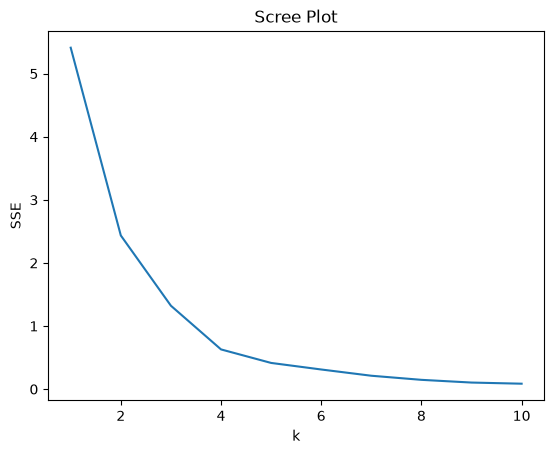

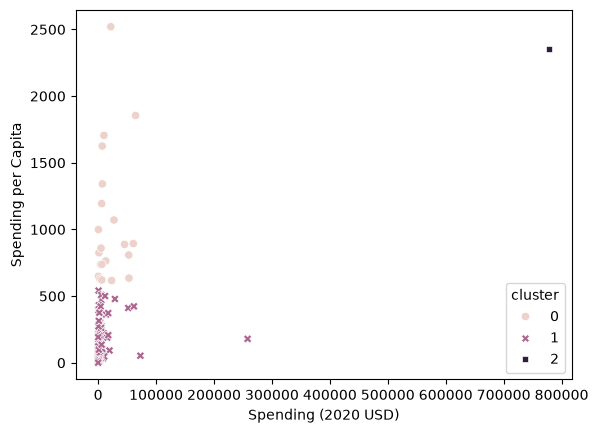

236          Australia
338            Bahrain
678             Brunei
882             Canada
1426           Denmark
1834           Finland
1868            France
2038           Germany
2582            Israel
2854      Korea, South
2922            Kuwait
3228        Luxembourg
3806       Netherlands
3840       New Zealand
4010            Norway
4044              Oman
4486      Saudi Arabia
4656         Singapore
4962            Sweden
4996       Switzerland
5506    United Kingdom
Name: Country, dtype: str
5540    United States of America
Name: Country, dtype: str


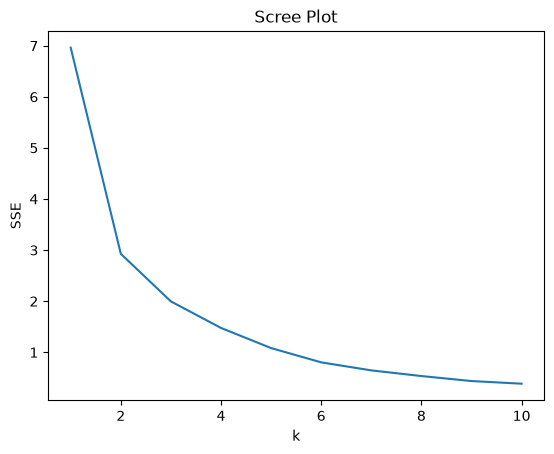

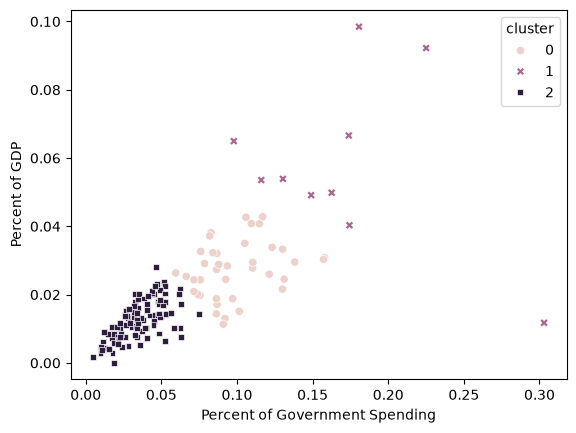

100          Algeria
202          Armenia
304       Azerbaijan
406          Belarus
2582          Israel
2718          Jordan
2922          Kuwait
4044            Oman
4078        Pakistan
4486    Saudi Arabia
Name: Country, dtype: str


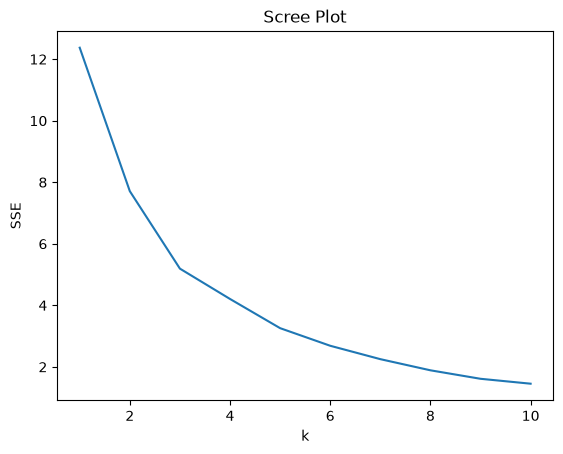

100               Algeria
202               Armenia
304            Azerbaijan
338               Bahrain
406               Belarus
610              Botswana
678                Brunei
746          Burkina Faso
814              Cambodia
984                  Chad
1086             Colombia
1154      Congo, Republic
1630    Equatorial Guinea
2412                India
2480                 Iran
2514                 Iraq
2718               Jordan
2854         Korea, South
3058              Lebanon
3364                 Mali
3432           Mauritania
3636              Morocco
3704              Myanmar
3738              Namibia
4078             Pakistan
4418               Russia
5064               Taiwan
5234                 Togo
5302              Tunisia
5404               Uganda
5438              Ukraine
Name: Country, dtype: str
2582                      Israel
2922                      Kuwait
4044                        Oman
4486                Saudi Arabia
4656                   Singapore
554

In [28]:
#Q2 part 1
df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
df = df[df["Year"] == 2020]
df = df.dropna()
print(df.shape)
df.describe()
#I got 148 countries too, and all four numeric columns already load as numbers, so there’s nothing to convert. The index and Year columns aren’t useful for clustering, since one is just a row number and the other is 2020 for every row. Keep in mind that the percent columns are stored as decimals (0.037 = 3.7%) and spending is in millions of dollars. The spending variables are also really skewed, and the US alone is huge enough to dominate a distance-based method like k-means.

#--------------------------------------------

#Q2 part 2
# max-min normalize
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

# scree plot
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

# fit k means with k = 3
model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_

sns.scatterplot(data=df, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster", style="cluster")
plt.show()

df.groupby("cluster")[features].describe()

# where is the US?
df[df["Country"] == "United States of America"]

# which countries are in each cluster?
print(df[df["cluster"] == 0]["Country"])
print(df[df["cluster"] == 2]["Country"])

#The scree plot bends around k = 3, so I used 3 clusters, and they came out really lopsided. The US gets its own cluster, 21 wealthy countries like the UK, Germany, Israel and Saudi Arabia form a second group at about $1,050 per person, and the other 126 countries sit at about $120 per person. So the clusters mostly split on how rich a country is, with the US in a league of its own. Interestingly, China spends about $258B total but still lands in the “everyone else” group, because it only spends about $180 per person.

#--------------------------------------------

#Q2 part 3
# max-min normalize
features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

# scree plot
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

# fit k means with k = 3
model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_

sns.scatterplot(data=df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster", style="cluster")
plt.show()

df.groupby("cluster")[features].describe()

# where is the US?
df[df["Country"] == "United States of America"]

# which countries are in the high cluster?
print(df[df["cluster"] == 1]["Country"])

#The scree plot bends at 2–3, and with k = 3 the clusters are much more balanced: 99 low-priority countries, 39 medium ones and 10 high ones. The US lands in the middle group with China and Russia, while the high group is mostly conflict-heavy countries like Israel, Saudi Arabia, Pakistan and Armenia. Compared with Part 2, this grouping is totally different, because these variables measure how much of a priority the military is, not how much money gets spent. The split is also more even, since percentages aren’t nearly as skewed as raw dollars.

#--------------------------------------------

#Q2 part 4
# max-min normalize all four
features = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

# scree plot
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

# fit k means with k = 3
model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_

df.groupby("cluster")[features].describe()

# where is the US, and who is in each cluster?
df[df["Country"] == "United States of America"]
print(df[df["cluster"] == 1]["Country"])
print(df[df["cluster"] == 2]["Country"])

#With all four variables the elbow is softer, but there’s still a bend at 3. Six countries (the US, Saudi Arabia, Israel, Kuwait, Oman and Singapore) are high on every measure, 31 countries like Russia, India and Pakistan put a big share of their economy into the military but spend little per person, and the other 111 are low on everything. This basically combines Parts 2 and 3, and the US isn’t alone anymore because its percentages look similar to the Gulf states and Israel. The tradeoff is a less clear elbow, since more variables give the groups more room to blend together.

#--------------------------------------------

#Q2 part 5
#Kind of. It found some real patterns, like richer countries spending more per person, conflict-heavy regions putting more of their economy into the military, and a small group of wealthy, security-focused countries standing out on every measure. But the skewed spending data gave the US its own cluster, and the results changed a lot depending on which variables I picked. So it’s good for exploring the data, but it doesn’t give one “right” answer, and a log transform on spending would probably balance things out.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]